Import Required Libraries

We import NumPy and Pandas for numerical operations and data manipulation. Matplotlib and Seaborn are used later for data visualization.

In [2]:
# pip install -r ../requirements.txt

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

Load Dataset

The Penguins dataset is loaded using Pandas. We use the CSV file provided for this project

In [4]:
df = pd.read_csv("../data/raw/penguins_size.csv")

df.head()

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


Dataset Dimensions

We check the number of rows and columns to understand the size of the dataset.

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 344
Number of columns: 7


Dataset Information

We inspect the column names, data types, and non-null values. This helps us identify numerical and categorical features and detect columns containing missing values.

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB


Missing Value Analysis

Missing values can affect machine learning models. Therefore, we check every column to determine how many missing values are present before deciding how to handle them.

In [7]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


Target Variable Distribution

The target variable for this project is species. We examine the number of records belonging to each penguin species to understand whether the classes are balanced.

In [8]:
print(df["species"].value_counts())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


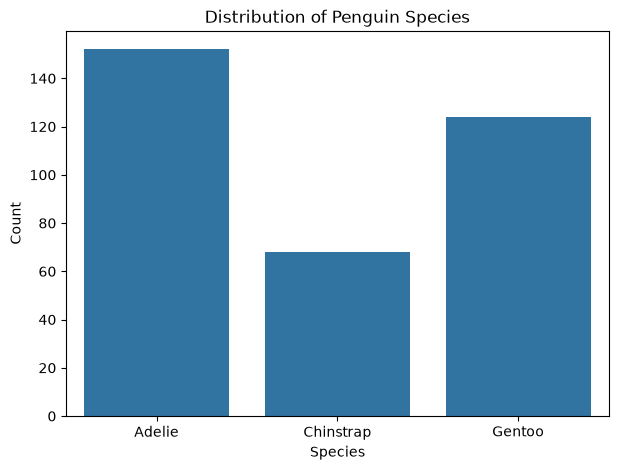

In [9]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Penguin Species")
plt.xlabel("Species")
plt.ylabel("Count")
plt.show()

Statistical Summary

We use descriptive statistics to understand the distribution of numerical variables such as bill length, bill depth, flipper length, and body mass.

In [10]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


Categorical Feature Analysis

We identify categorical columns because machine learning algorithms generally require categorical values to be converted into numerical representations.

In [11]:
categorical_columns = df.select_dtypes(include="object").columns

print("Categorical columns:")
print(list(categorical_columns))

Categorical columns:
['species', 'island', 'sex']


C:\Users\Dell\AppData\Local\Temp\ipykernel_24432\2798951942.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


Missing Value Analysis

The dataset contains missing values in five features. Since the target variable species has no missing values, all records can potentially be used for classification. Numerical missing values will be handled using an appropriate statistical method, while the categorical sex feature will be handled separately. Before applying imputation, we inspect the missing records to understand their distribution.

In [12]:
# Display rows containing missing values

df[df.isnull().any(axis=1)]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


In [13]:
# Count missing values in each column

missing_values = df.isnull().sum()

print(missing_values)

species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  10
dtype: int64


Categorical Feature Analysis

We inspect the unique values in categorical columns before encoding them. This helps us understand the categories present in the dataset and identify any unexpected values.

In [14]:
print("Species:")
print(df["species"].unique())

print("\nIsland:")
print(df["island"].unique())

print("\nSex:")
print(df["sex"].unique())

Species:
<StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str

Island:
<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str

Sex:
<StringArray>
['MALE', 'FEMALE', nan, '.']
Length: 4, dtype: str


In [15]:
df.describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


In [16]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
culmen_length_mm,342.0,43.921930,5.459584,32.1,39.225,44.45,48.5,59.6
culmen_depth_mm,342.0,17.151170,1.974793,13.1,15.600,17.30,18.7,21.5
flipper_length_mm,342.0,200.915205,14.061714,172.0,190.000,197.00,213.0,231.0
body_mass_g,342.0,4201.754386,801.954536,2700.0,3550.000,4050.00,4750.0,6300.0


In [17]:
df[df.isnull().any(axis=1)]

,species,island,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN
47,Adelie,Dream,37.5,18.9,179.0,2975.0,NaN
246,Gentoo,Biscoe,44.5,14.3,216.0,4100.0,NaN
286,Gentoo,Biscoe,46.2,14.4,214.0,4650.0,NaN
324,Gentoo,Biscoe,47.3,13.8,216.0,4725.0,NaN
339,Gentoo,Biscoe,NaN,NaN,NaN,NaN,NaN


In [18]:
df["sex"].unique()

<StringArray>
['MALE', 'FEMALE', nan, '.']
Length: 4, dtype: str

In [19]:
print("Species:")
print(df["species"].unique())

print("\nIsland:")
print(df["island"].unique())

print("\nSex:")
print(df["sex"].unique())

Species:
<StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str

Island:
<StringArray>
['Torgersen', 'Biscoe', 'Dream']
Length: 3, dtype: str

Sex:
<StringArray>
['MALE', 'FEMALE', nan, '.']
Length: 4, dtype: str


In [20]:
print(df["species"].value_counts())

species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


Numerical Feature Distribution

Boxplots are used to examine the distribution of numerical features and identify potential extreme observations. An observation identified as an outlier will not automatically be removed; its effect on the dataset and model will be considered before deciding whether treatment is necessary.

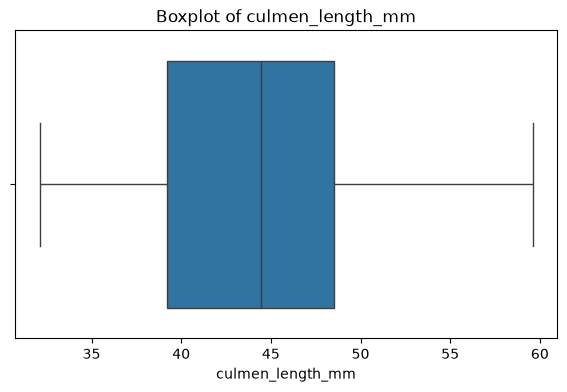

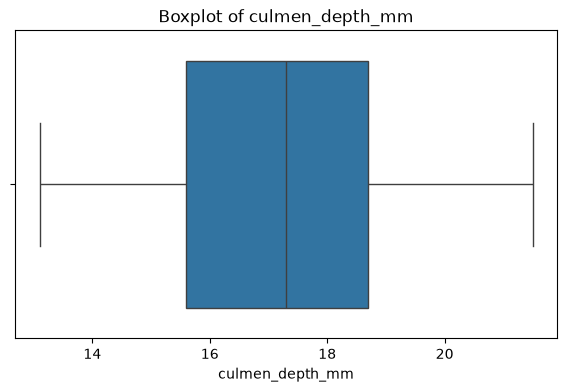

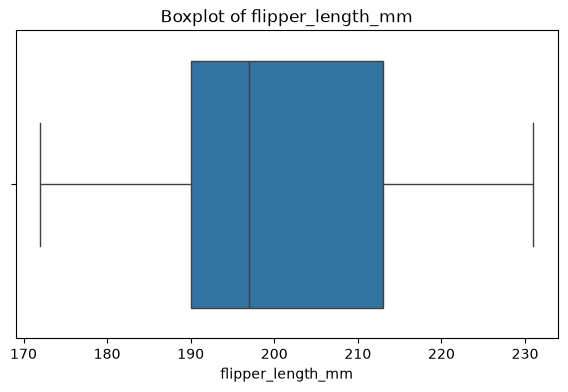

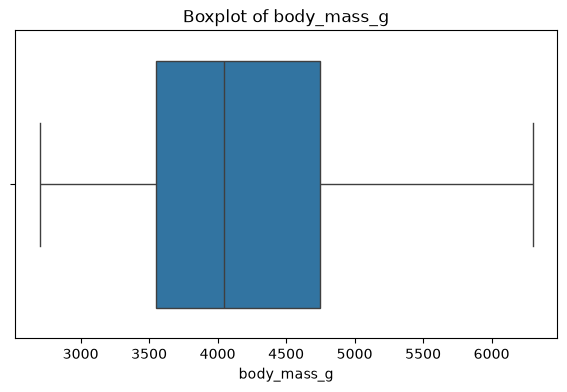

In [21]:
numerical_columns = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

for column in numerical_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.show()

## Outlier Analysis

Outliers are observations that are unusually high or low compared with the rest of the data.

We use boxplots to visually identify potential outliers in the numerical features. However, an observation appearing as an outlier does not automatically mean that it should be removed. Since the measurements represent real penguin characteristics, extreme values may be genuine observations.

Therefore, we will inspect the distributions first and decide whether outlier treatment is necessary.

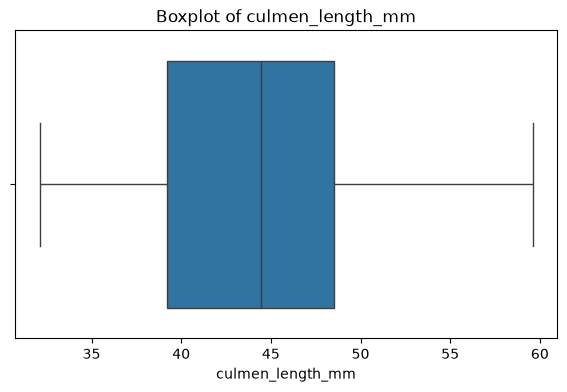

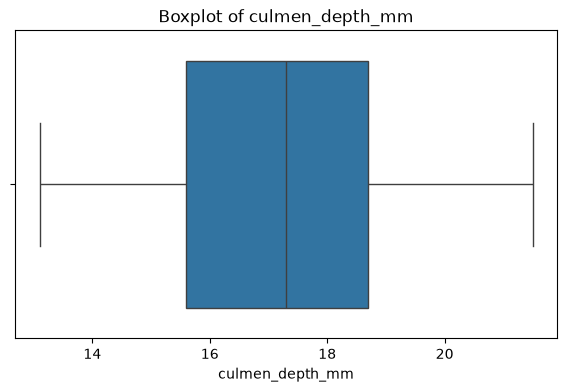

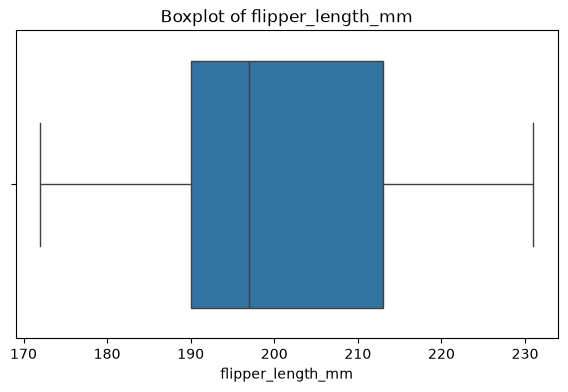

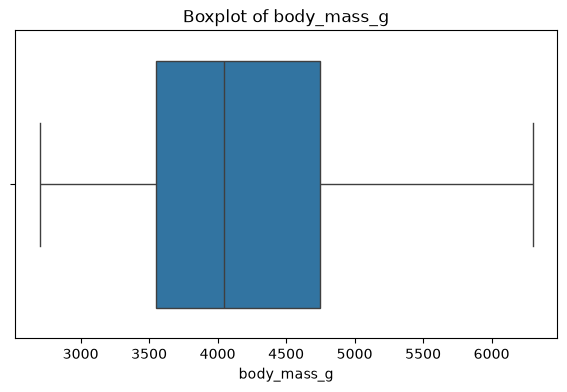

In [22]:
numerical_columns = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

for column in numerical_columns:
    plt.figure(figsize=(7, 4))
    sns.boxplot(x=df[column])
    plt.title(f"Boxplot of {column}")
    plt.xlabel(column)
    plt.show()

## Statistical Summary of Numerical Features

Descriptive statistics help us understand the central tendency and spread of the numerical features.

We calculate the count, mean, standard deviation, minimum, quartiles, and maximum values. This information helps us understand the range of the penguin measurements and supports our decision about outliers and preprocessing.

In [23]:
df[numerical_columns].describe()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


## Categorical Feature Analysis

The dataset contains categorical features such as species, island, and sex.

We examine the unique categories and their frequencies to understand the distribution of these variables before applying categorical encoding during preprocessing.

In [24]:
categorical_columns = ["species", "island", "sex"]

for column in categorical_columns:
    print(f"\n{column.upper()}")
    print(df[column].value_counts(dropna=False))


SPECIES
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

ISLAND
island
Biscoe       168
Dream        124
Torgersen     52
Name: count, dtype: int64

SEX
sex
MALE      168
FEMALE    165
NaN        10
.           1
Name: count, dtype: int64


## Species Distribution

The target variable of this project is `species`.

We visualize the number of penguins belonging to each species. This helps us understand the distribution of the target classes and determine whether there is a significant class imbalance.

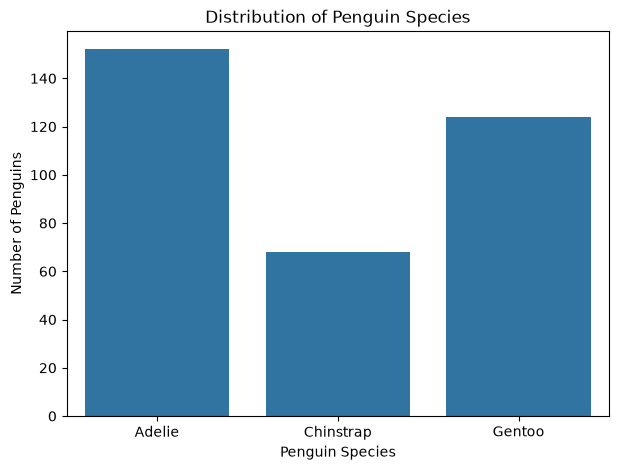

In [25]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="species")

plt.title("Distribution of Penguin Species")
plt.xlabel("Penguin Species")
plt.ylabel("Number of Penguins")
plt.show()

## Data Cleaning: Handling Invalid Missing Values

The `sex` column contains one value represented by a period (`.`). This does not represent a valid category and should be treated as a missing value.

We replace this invalid value with `NaN` so that it can be handled consistently with the other missing values during preprocessing.

In [26]:
# Replace invalid "." values with NaN

df["sex"] = df["sex"].replace(".", np.nan)

print("Missing values after correction:")
print(df.isnull().sum())

Missing values after correction:
species               0
island                0
culmen_length_mm      2
culmen_depth_mm       2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


## Missing Value Summary

After correcting the invalid value in the `sex` column, we check the dataset again to determine the number of missing values in each feature.

This allows us to confirm that the invalid category has been correctly converted to a missing value before performing imputation.

In [27]:
missing_summary = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Missing Percentage": (df.isnull().sum() / len(df)) * 100
})

missing_summary

,Missing Values,Missing Percentage
species,0,0.000000
island,0,0.000000
culmen_length_mm,2,0.581395
culmen_depth_mm,2,0.581395
flipper_length_mm,2,0.581395
body_mass_g,2,0.581395
sex,11,3.197674


## Exploratory Data Analysis: Numerical Features by Species

We compare the numerical features across penguin species to understand how physical characteristics vary between the three classes.

Boxplots are useful for comparing the distribution, median, spread, and potential differences in each numerical feature across species.

These observations can also help us understand which features may be useful for predicting penguin species.

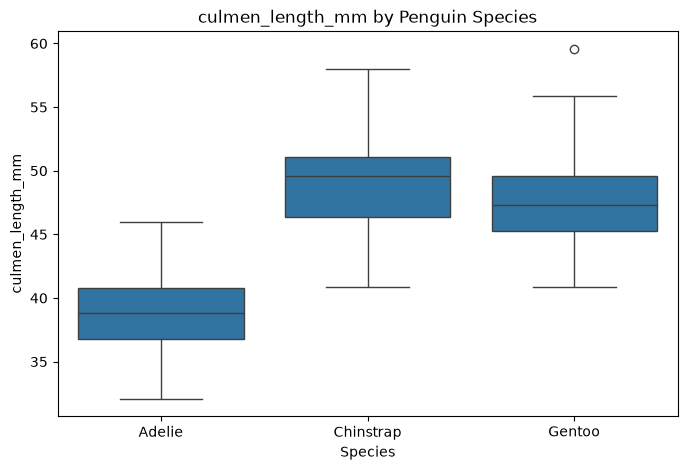

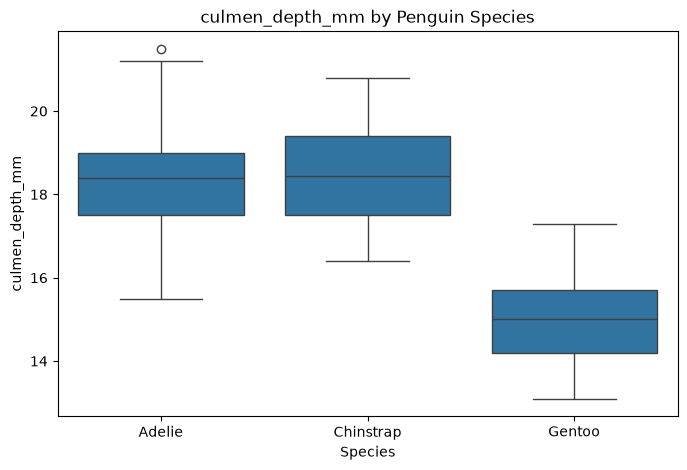

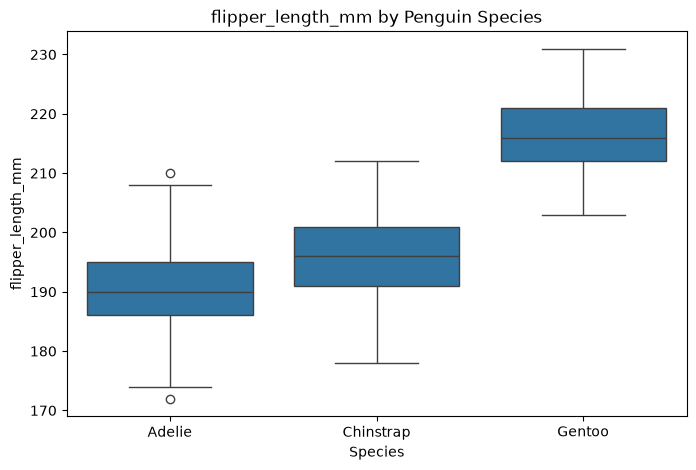

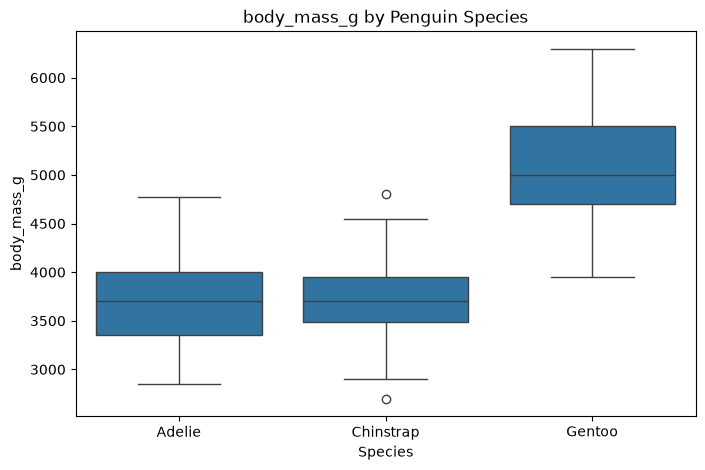

In [28]:
for column in numerical_columns:
    plt.figure(figsize=(8, 5))
    
    sns.boxplot(data=df, x="species", y=column)
    
    plt.title(f"{column} by Penguin Species")
    plt.xlabel("Species")
    plt.ylabel(column)
    plt.show()

## Feature Relationship Analysis

Scatter plots help us examine relationships between numerical features and determine whether different penguin species form distinct patterns.

We compare bill length with bill depth and use species as the grouping variable. This helps us visually assess whether these measurements can help distinguish the target classes.

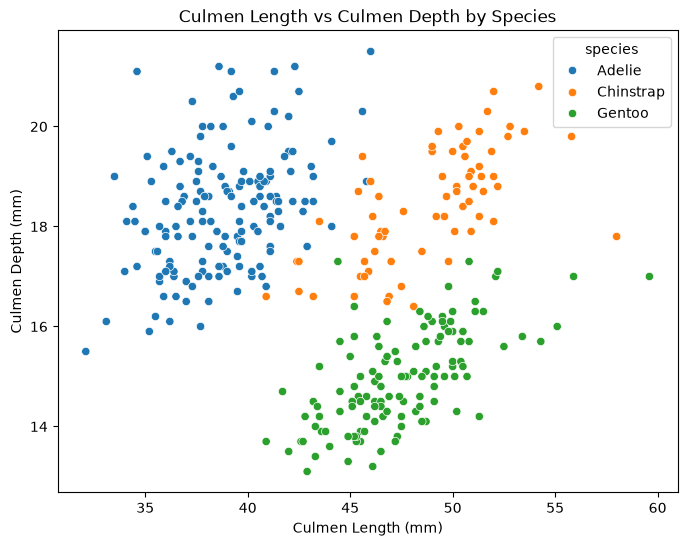

In [29]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="culmen_length_mm",
    y="culmen_depth_mm",
    hue="species"
)

plt.title("Culmen Length vs Culmen Depth by Species")
plt.xlabel("Culmen Length (mm)")
plt.ylabel("Culmen Depth (mm)")
plt.show()

## Correlation Analysis

Correlation measures the strength and direction of a linear relationship between numerical variables.

We calculate the correlation matrix to understand how the numerical features are related to each other. This can help identify highly related features and provide additional insight during feature selection.

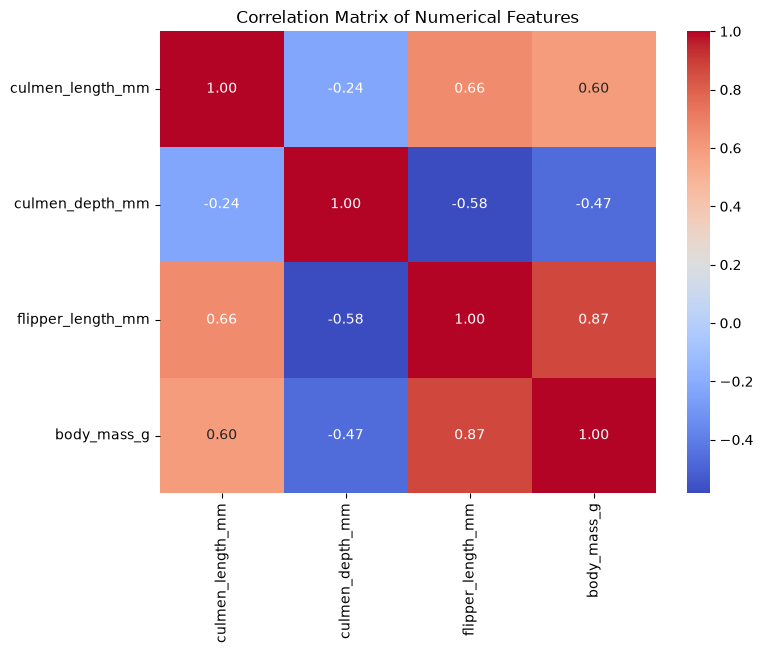

In [30]:
plt.figure(figsize=(8, 6))

correlation_matrix = df[numerical_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Matrix of Numerical Features")
plt.show()

### Correlation Analysis Observation

The correlation matrix shows several relationships among the numerical features. The strongest relationship is between flipper length and body mass, with a correlation of 0.87, indicating a strong positive relationship.

Culmen length also has moderate positive relationships with flipper length and body mass. Culmen depth has moderate negative relationships with flipper length and body mass.

Although flipper length and body mass are strongly correlated, both features are retained initially because they may provide useful information for distinguishing penguin species. Feature importance and model performance will be considered before making any feature removal decision.

## Data Preprocessing

Before training machine learning models, the dataset must be separated into input features and the target variable.

The target variable is `species`, which represents the penguin species we want to predict. The remaining relevant columns will be used as input features.

The target column is separated from the input features to prevent the model from using the answer itself during training.

In [31]:
# Separate features and target

X = df.drop("species", axis=1)
y = df["species"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['island', 'culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Target:
species


## Train-Test Split

The dataset is divided into training and testing sets.

The training data is used to learn patterns from the dataset, while the testing data is kept separate and used to evaluate how well the trained model performs on unseen data.

We use an 80:20 split, meaning 80% of the observations are used for training and 20% for testing. Stratification is applied using the target variable so that the proportion of each penguin species remains similar in both sets.

In [32]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 275
Testing samples: 69


## Identify Numerical and Categorical Features

The dataset contains both numerical and categorical features.

Numerical features require missing-value imputation and scaling, while categorical features require missing-value handling and encoding.

We separate these feature types so that different preprocessing techniques can be applied appropriately.

In [33]:
# Define numerical and categorical features

numerical_features = [
    "culmen_length_mm",
    "culmen_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]

categorical_features = [
    "island",
    "sex"
]

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

Categorical features:
['island', 'sex']


## Create Preprocessing Pipelines

Different preprocessing techniques are required for numerical and categorical features.

For numerical features:
- Missing values are replaced using the median.
- StandardScaler is used to standardize the features.

For categorical features:
- Missing values are replaced using the most frequent category.
- OneHotEncoder converts categorical values into numerical form.

A pipeline is used to ensure that preprocessing steps are learned only from the training data and then consistently applied to the testing data. This helps prevent data leakage.

In [34]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numerical", numerical_pipeline, numerical_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


## Apply Preprocessing to the Training Data

The preprocessing pipeline is fitted using the training data only. It learns the required imputation values, scaling parameters, and categorical encoding from the training set.

The same learned transformations will later be applied to the test set without fitting them again.

In [35]:
# Fit preprocessing on training data and transform it

X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the already fitted preprocessor

X_test_processed = preprocessor.transform(X_test)

print("Processed training data shape:", X_train_processed.shape)
print("Processed testing data shape:", X_test_processed.shape)

Processed training data shape: (275, 9)
Processed testing data shape: (69, 9)


## Verify Missing Value Handling

After preprocessing, we verify that the numerical and categorical missing values have been handled successfully.

The imputation steps should ensure that the data passed to the machine learning models does not contain missing values.

In [36]:
import numpy as np

print("Missing values in training data:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing data:",
      np.isnan(X_test_processed).sum())

Missing values in training data: 0
Missing values in testing data: 0


## Verify Target Classes

The target variable contains three penguin species. We verify the target classes before training the classification models.

Since this is a multiclass classification problem, the models will learn to distinguish among Adelie, Chinstrap, and Gentoo penguins.

In [37]:
print("Target classes:")
print(y.unique())

print("\nTraining target distribution:")
print(y_train.value_counts())

Target classes:
<StringArray>
['Adelie', 'Chinstrap', 'Gentoo']
Length: 3, dtype: str

Training target distribution:
species
Adelie       122
Gentoo        99
Chinstrap     54
Name: count, dtype: int64


## Preparing Training and Testing Data

The preprocessing pipeline is applied to the training and testing feature sets. The preprocessing is fitted on the training data and then used to transform the test data, preventing information from the test set from influencing the training process.

In [38]:
# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the fitted preprocessing to test data
X_test_processed = preprocessor.transform(X_test)

print("Training data shape after preprocessing:", X_train_processed.shape)
print("Testing data shape after preprocessing:", X_test_processed.shape)

Training data shape after preprocessing: (275, 9)
Testing data shape after preprocessing: (69, 9)


## 1. Logistic Regression

Logistic Regression is used as the first classification model for predicting penguin species. The model is trained using the preprocessed training data and evaluated on the held-out test data using accuracy, precision, recall, and F1-score.

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Create Logistic Regression model
logistic_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train the model
logistic_model.fit(X_train_processed, y_train)

# Predict on test data
y_pred_lr = logistic_model.predict(X_test_processed)

# Evaluate the model
lr_accuracy = accuracy_score(y_test, y_pred_lr)
lr_precision = precision_score(y_test, y_pred_lr, average="weighted", zero_division=0)
lr_recall = recall_score(y_test, y_pred_lr, average="weighted", zero_division=0)
lr_f1 = f1_score(y_test, y_pred_lr, average="weighted", zero_division=0)

print("Logistic Regression Evaluation")
print("--------------------------------")
print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1-Score : {lr_f1:.4f}")

Logistic Regression Evaluation
--------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000


### Logistic Regression – Confusion Matrix

The confusion matrix shows the number of correctly and incorrectly classified penguin species for the Logistic Regression model. Correct predictions appear along the diagonal, while incorrect predictions appear in the off-diagonal cells.

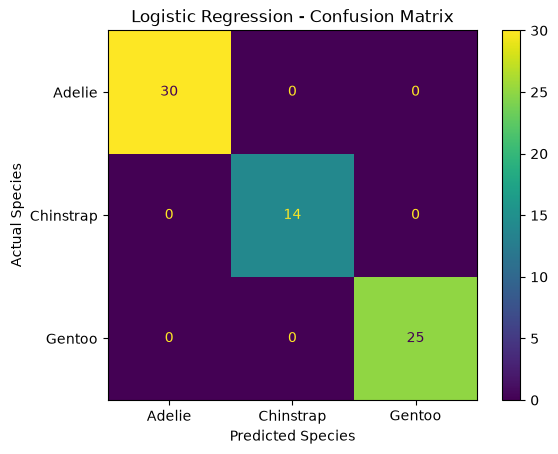

In [40]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    display_labels=logistic_model.classes_
)

plt.title("Logistic Regression - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

## 2. Decision Tree

Decision Tree is used as the second classification model for predicting penguin species. The model learns decision rules from the training data and is evaluated on the held-out test data using accuracy, precision, recall, and F1-score.

In [41]:
from sklearn.tree import DecisionTreeClassifier

# Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train_processed, y_train)

# Predict on test data
y_pred_dt = decision_tree_model.predict(X_test_processed)

# Evaluate the model
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(
    y_test, y_pred_dt, average="weighted", zero_division=0
)
dt_recall = recall_score(
    y_test, y_pred_dt, average="weighted", zero_division=0
)
dt_f1 = f1_score(
    y_test, y_pred_dt, average="weighted", zero_division=0
)

print("Decision Tree Evaluation")
print("--------------------------------")
print(f"Accuracy : {dt_accuracy:.4f}")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall   : {dt_recall:.4f}")
print(f"F1-Score : {dt_f1:.4f}")

Decision Tree Evaluation
--------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000


### Decision Tree – Confusion Matrix

The confusion matrix is used to examine the classification performance of the Decision Tree model for each penguin species.

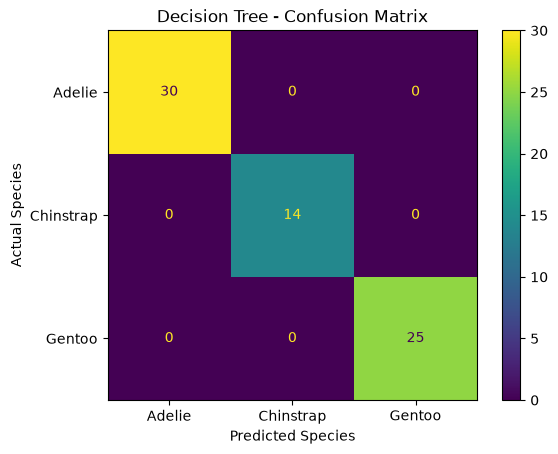

In [42]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    display_labels=decision_tree_model.classes_
)

plt.title("Decision Tree - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

## 3. Random Forest

Random Forest is an ensemble classification algorithm that combines multiple decision trees to improve predictive performance and robustness. The model is trained on the preprocessed training data and evaluated on the held-out test data using accuracy, precision, recall, and F1-score.

In [43]:
from sklearn.ensemble import RandomForestClassifier

# Create Random Forest model
random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the model
random_forest_model.fit(X_train_processed, y_train)

# Predict on test data
y_pred_rf = random_forest_model.predict(X_test_processed)

# Evaluate the model
rf_accuracy = accuracy_score(y_test, y_pred_rf)
rf_precision = precision_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
rf_recall = recall_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)
rf_f1 = f1_score(
    y_test, y_pred_rf, average="weighted", zero_division=0
)

print("Random Forest Evaluation")
print("--------------------------------")
print(f"Accuracy : {rf_accuracy:.4f}")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall   : {rf_recall:.4f}")
print(f"F1-Score : {rf_f1:.4f}")

Random Forest Evaluation
--------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000


### Random Forest – Confusion Matrix

The confusion matrix shows the classification results of the Random Forest model for the three penguin species.

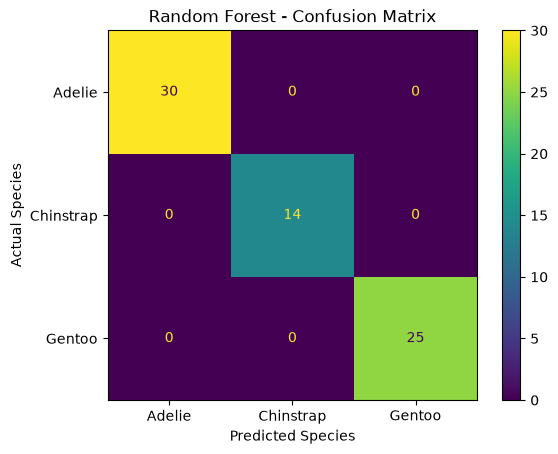

In [44]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=random_forest_model.classes_
)

plt.title("Random Forest - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

## 4. Support Vector Machine

Support Vector Machine (SVM) is used as the fourth classification model for predicting penguin species. SVM attempts to find an effective decision boundary between the different species. The model is trained using the preprocessed training data and evaluated on the held-out test data using accuracy, precision, recall, and F1-score.

In [45]:
from sklearn.svm import SVC

# Create SVM model
svm_model = SVC(random_state=42)

# Train the model
svm_model.fit(X_train_processed, y_train)

# Predict on test data
y_pred_svm = svm_model.predict(X_test_processed)

# Evaluate the model
svm_accuracy = accuracy_score(y_test, y_pred_svm)
svm_precision = precision_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)
svm_recall = recall_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)
svm_f1 = f1_score(
    y_test, y_pred_svm, average="weighted", zero_division=0
)

print("SVM Evaluation")
print("--------------------------------")
print(f"Accuracy : {svm_accuracy:.4f}")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall   : {svm_recall:.4f}")
print(f"F1-Score : {svm_f1:.4f}")

SVM Evaluation
--------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000


### SVM – Confusion Matrix

The confusion matrix is used to analyze the classification performance of the SVM model across Adelie, Chinstrap, and Gentoo penguins.

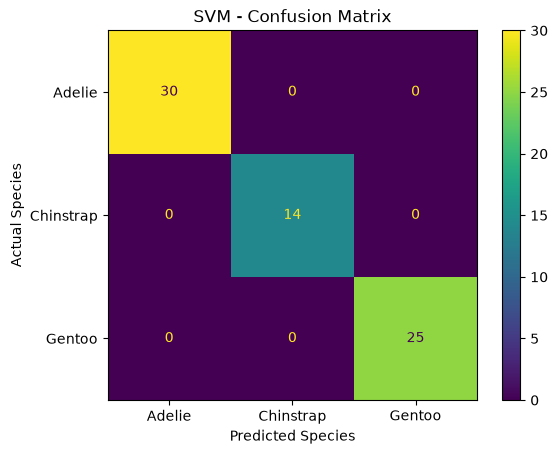

In [46]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_svm,
    display_labels=svm_model.classes_
)

plt.title("SVM - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

## 5. K-Nearest Neighbors

K-Nearest Neighbors (KNN) is used as the fifth classification model. The algorithm classifies a new observation based on the classes of its nearest training observations. The model is trained using the preprocessed training data and evaluated on the held-out test data using accuracy, precision, recall, and F1-score.

In [47]:
from sklearn.neighbors import KNeighborsClassifier

# Create KNN model
knn_model = KNeighborsClassifier()

# Train the model
knn_model.fit(X_train_processed, y_train)

# Predict on test data
y_pred_knn = knn_model.predict(X_test_processed)

# Evaluate the model
knn_accuracy = accuracy_score(y_test, y_pred_knn)
knn_precision = precision_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
)
knn_recall = recall_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
)
knn_f1 = f1_score(
    y_test, y_pred_knn, average="weighted", zero_division=0
)

print("KNN Evaluation")
print("--------------------------------")
print(f"Accuracy : {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall   : {knn_recall:.4f}")
print(f"F1-Score : {knn_f1:.4f}")

KNN Evaluation
--------------------------------
Accuracy : 0.9855
Precision: 0.9865
Recall   : 0.9855
F1-Score : 0.9856


### KNN – Confusion Matrix

The confusion matrix shows the correct and incorrect classifications produced by the KNN model for each penguin species.

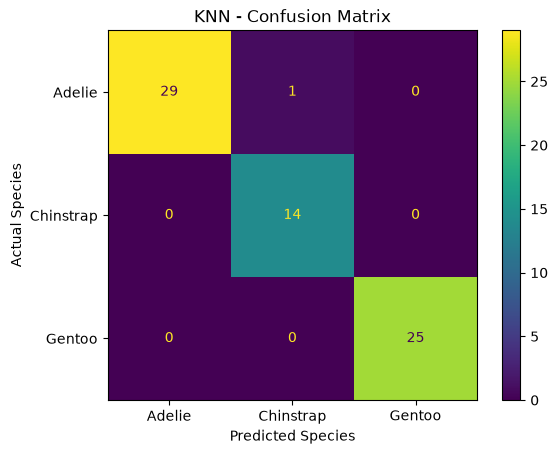

In [48]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_knn,
    display_labels=knn_model.classes_
)

plt.title("KNN - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

##  Overall Model Comparison

The five classification models are compared using accuracy, precision, recall, and F1-score. These metrics provide a comprehensive view of the classification performance of each model.

The comparison is used to identify candidate models for further validation and hyperparameter tuning.

In [49]:
# Create overall model comparison table

results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "SVM",
        "KNN"
    ],
    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        svm_accuracy,
        knn_accuracy
    ],
    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision,
        svm_precision,
        knn_precision
    ],
    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall,
        svm_recall,
        knn_recall
    ],
    "F1-Score": [
        lr_f1,
        dt_f1,
        rf_f1,
        svm_f1,
        knn_f1
    ]
})

results_df

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,1.000000,1.000000,1.000000,1.000000
1,Decision Tree,1.000000,1.000000,1.000000,1.000000
2,Random Forest,1.000000,1.000000,1.000000,1.000000
3,SVM,1.000000,1.000000,1.000000,1.000000
4,KNN,0.985507,0.986473,0.985507,0.985634


### Interpretation

The test-set evaluation shows that Logistic Regression, Decision Tree, Random Forest, and SVM achieved perfect scores on the held-out test data. KNN achieved a slightly lower accuracy of 98.55%.

Since multiple models obtained the same test accuracy, test accuracy alone is not sufficient to select the final model. Therefore, cross-validation is performed to obtain a more reliable comparison of model performance.

##  Model Validation Using Cross-Validation

Five-fold stratified cross-validation is used to obtain a more reliable estimate of model performance. The training data is divided into five folds while preserving the class distribution. Each model is trained on four folds and validated on the remaining fold. This process is repeated five times, and the mean and standard deviation of accuracy are calculated.

In [50]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline

# Define 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Store cross-validation results
cv_results = []

# Logistic Regression
lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

lr_scores = cross_val_score(
    lr_pipeline, X_train, y_train,
    cv=cv, scoring="accuracy"
)

cv_results.append([
    "Logistic Regression",
    lr_scores.mean(),
    lr_scores.std()
])


# Decision Tree
dt_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(random_state=42))
])

dt_scores = cross_val_score(
    dt_pipeline, X_train, y_train,
    cv=cv, scoring="accuracy"
)

cv_results.append([
    "Decision Tree",
    dt_scores.mean(),
    dt_scores.std()
])


# Random Forest
rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ))
])

rf_scores = cross_val_score(
    rf_pipeline, X_train, y_train,
    cv=cv, scoring="accuracy"
)

cv_results.append([
    "Random Forest",
    rf_scores.mean(),
    rf_scores.std()
])


# SVM
svm_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(random_state=42))
])

svm_scores = cross_val_score(
    svm_pipeline, X_train, y_train,
    cv=cv, scoring="accuracy"
)

cv_results.append([
    "SVM",
    svm_scores.mean(),
    svm_scores.std()
])


# KNN
knn_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier())
])

knn_scores = cross_val_score(
    knn_pipeline, X_train, y_train,
    cv=cv, scoring="accuracy"
)

cv_results.append([
    "KNN",
    knn_scores.mean(),
    knn_scores.std()
])

In [51]:
cv_results_df = pd.DataFrame(
    cv_results,
    columns=[
        "Model",
        "Mean CV Accuracy",
        "Std CV Accuracy"
    ]
)

cv_results_df = cv_results_df.sort_values(
    by="Mean CV Accuracy",
    ascending=False
).reset_index(drop=True)

cv_results_df

,Model,Mean CV Accuracy,Std CV Accuracy
0,Logistic Regression,0.992727,0.008907
1,SVM,0.992727,0.008907
2,KNN,0.989091,0.014545
3,Random Forest,0.981818,0.019917
4,Decision Tree,0.949091,0.042094


In [52]:
print("Logistic Regression:", lr_scores)
print("SVM:", svm_scores)

Logistic Regression: [0.98181818 1.         1.         0.98181818 1.        ]
SVM: [0.98181818 1.         1.         0.98181818 1.        ]


### Cross-Validation Interpretation

The cross-validation results show that Logistic Regression and SVM achieved the same highest mean accuracy of 99.27%, with an identical standard deviation of 0.89%. They are followed by KNN at 98.91%, Random Forest at 98.18%, and Decision Tree at 94.91%, which also showed the largest variation between folds (standard deviation of 4.21%).

Because Logistic Regression and SVM are tied on both mean accuracy and stability, cross-validation alone does not identify a single best model. SVM is chosen as the candidate for further hyperparameter tuning because its regularization parameter `C` and kernel coefficient `gamma` give a well-defined search space; this is a modelling choice, not a claim that SVM outperformed Logistic Regression.

## Hyperparameter Tuning of SVM

SVM was selected as a candidate for further tuning (it tied with Logistic Regression for the highest mean cross-validation accuracy), so hyperparameter tuning is performed to identify suitable values for the regularization parameter C and the kernel coefficient gamma.

GridSearchCV evaluates different combinations of these hyperparameters using cross-validation and selects the combination that provides the highest validation accuracy.

In [53]:
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

# Create SVM pipeline
svm_tuning_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC(random_state=42))
])

# Define hyperparameter values
param_grid = {
    "model__C": [0.1, 1, 10, 100],
    "model__gamma": ["scale", "auto", 0.01, 0.1, 1]
}

# Create GridSearchCV
grid_search = GridSearchCV(
    estimator=svm_tuning_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

# Perform hyperparameter tuning
grid_search.fit(X_train, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation Accuracy:", grid_search.best_score_)

Best Parameters: {'model__C': 1, 'model__gamma': 'scale'}
Best Cross-Validation Accuracy: 0.9927272727272728


##  Final Tuned SVM Evaluation

The SVM model with the best hyperparameters obtained from GridSearchCV is evaluated on the held-out test dataset. This provides the final performance estimate of the selected model on previously unseen test observations.

In [54]:
# Get the best SVM pipeline
best_svm = grid_search.best_estimator_

# Predict on the test dataset
y_pred_best_svm = best_svm.predict(X_test)

# Calculate evaluation metrics
best_svm_accuracy = accuracy_score(y_test, y_pred_best_svm)
best_svm_precision = precision_score(
    y_test,
    y_pred_best_svm,
    average="weighted",
    zero_division=0
)
best_svm_recall = recall_score(
    y_test,
    y_pred_best_svm,
    average="weighted",
    zero_division=0
)
best_svm_f1 = f1_score(
    y_test,
    y_pred_best_svm,
    average="weighted",
    zero_division=0
)

print("Tuned SVM Evaluation")
print("--------------------------------")
print(f"Accuracy : {best_svm_accuracy:.4f}")
print(f"Precision: {best_svm_precision:.4f}")
print(f"Recall   : {best_svm_recall:.4f}")
print(f"F1-Score : {best_svm_f1:.4f}")

Tuned SVM Evaluation
--------------------------------
Accuracy : 1.0000
Precision: 1.0000
Recall   : 1.0000
F1-Score : 1.0000


### Final Tuned SVM – Confusion Matrix

The confusion matrix of the final tuned SVM is presented to examine its classification performance on the held-out test dataset. It provides a class-wise view of the correct and incorrect predictions.

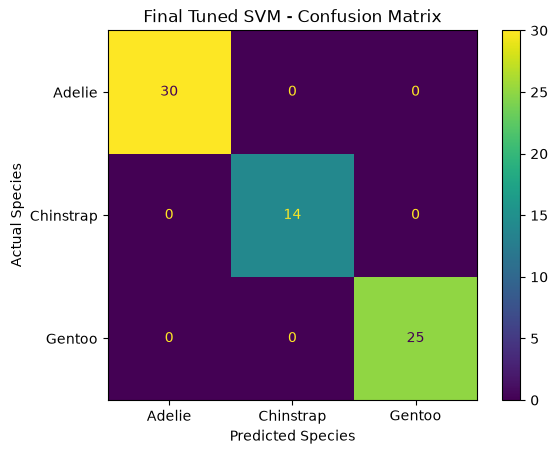

In [55]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best_svm,
    display_labels=best_svm.classes_
)

plt.title("Final Tuned SVM - Confusion Matrix")
plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.show()

In [56]:
from sklearn.metrics import classification_report

print("Classification Report:")
print(classification_report(y_test, y_pred_best_svm))

Classification Report:
              precision    recall  f1-score   support

      Adelie       1.00      1.00      1.00        30
   Chinstrap       1.00      1.00      1.00        14
      Gentoo       1.00      1.00      1.00        25

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



##  Sample / Unseen Data Prediction

The selected Support Vector Machine model is used to predict the species of a new penguin observation that was not part of the training dataset. This demonstrates how the final model can be applied to unseen data.

In [57]:
# Create a new unseen penguin observation

new_penguin = pd.DataFrame({
    "island": ["Biscoe"],
    "culmen_length_mm": [45.5],
    "culmen_depth_mm": [14.5],
    "flipper_length_mm": [215.0],
    "body_mass_g": [5000.0],
    "sex": ["MALE"]
})

# Predict the species
predicted_species = best_svm.predict(new_penguin)

print("Unseen Penguin Prediction")
print("--------------------------")
print("Predicted Species:", predicted_species[0])

Unseen Penguin Prediction
--------------------------
Predicted Species: Gentoo


## Conclusion

Five classification models were compared for predicting penguin species (Adelie, Chinstrap, Gentoo). On the held-out test set, Logistic Regression, Decision Tree, Random Forest and SVM all reached perfect scores, and KNN reached 98.55% accuracy. In five-fold cross-validation, Logistic Regression and SVM tied for the highest mean accuracy (99.27%, standard deviation 0.89%), ahead of KNN (98.91%), Random Forest (98.18%) and Decision Tree (94.91%).

SVM was taken forward for hyperparameter tuning as a modelling choice. GridSearchCV selected `C=1` and `gamma='scale'` (best cross-validation accuracy 99.27%), which is the same as the default SVM, and the tuned model again scored 100% on the test set. Since Logistic Regression performs equally well in cross-validation, the results do not show that SVM is uniquely the best model. The test set is small (69 penguins), so the perfect test scores should be read cautiously.